# Foundation 2: Temporal Telemetry, Statistical Imputation & Crowdsourced Demand
**Objective:** Prepare the two time-varying data sources. (1) The manually compiled 17-quarter macro-telemetry from the Communications Authority of Kenya (CA), with linear imputation of the missing data volumes for Q2–Q4 2022/23. (2) Ookla Open Data mobile performance tiles for the same 17 quarters, clipped to Kenya's border, which give a **local** demand signal that the national CA series cannot.

| | |
|---|---|
| **Pipeline** | 01 Spatial canvas → **02 Temporal extraction** → 03 Spatial downscale → 04 MTL engine → 05 Explainability & NDS |
| **Answers** | Research Question 2 and the second half of Specific Objective 1 (the demand indicators to be downscaled) |
| **Inputs** | `Data/processed/ca_quarterly_telemetry.csv` (compiled from CA quarterly sector statistics reports), `Data/raw_ookla/ookla_mobile_kenya_all_quarters.csv` |
| **Outputs** | `Data/processed/ca_quarterly_telemetry_imputed.csv`, `Data/processed/ookla_kenya_clean.parquet`; Tables 4.3–4.4; Figures 4.3–4.4 |

**The idea in one paragraph.** Notebook 01 built the *where* of the study: the approximate cell sites and their technology. This notebook builds the *when* and the *how much*: how much mobile data Kenya used in each quarter, and where in the country people were actively using mobile internet. Neither source is enough on its own. The CA series is a reliable national total but says nothing about location; the Ookla tiles show where activity is but are far too sparse to measure total traffic. Notebook 03 combines the two: the CA total sets how much demand there is in a quarter, and the Ookla tiles decide how that total is shared out across places.

**Key terms used in Part A**
- **Communications Authority of Kenya (CA) sector statistics:** the regulator's quarterly report with national figures such as mobile subscriptions, smartphones in use and the volume of mobile data consumed. For this study the needed figures were copied by hand from those reports into one CSV file, one row per quarter.
- **Macro-telemetry:** national-level (macro) measurements of network use over time, as opposed to measurements for individual places.
- **Financial-year quarters:** the CA works on a July–June financial year, so its Q1 is July–September, Q2 is October–December, Q3 is January–March and Q4 is April–June. A label such as `Q3_21_22` reads "quarter 3 of financial year 2021/22".
- **Imputation:** replacing missing values with estimates so that a series has no holes. **Linear** imputation draws a straight line between the known values on either side of the gap.

**Layout of the notebook:** Part A (Steps 1–2) prepares the CA national series; Part B (Steps 3–5) prepares the Ookla tiles; Step 6 saves the clean Ookla file for Notebook 03.

In [1]:
# Load the shared settings and helpers used by all five notebooks. The '*' imports every public
# name defined in project_config.py: pandas (pd), numpy (np), matplotlib (plt), os, the folder
# paths (PROCESSED, RAW_OOKLA, ...) and helpers such as save_table, save_figure and in_kenya.
from project_config import *
import warnings
# Hide warning messages (for example pandas notices about future changes) so the printed output
# stays readable. This only changes what is shown on screen, not any result.
warnings.filterwarnings('ignore')

## Part A: CA National Telemetry
### Step 1: Load the compiled series in chronological order
CA reports by financial year (July–June), so `Q3_21_22` is January–March 2022 and `Q3_25_26` is January–March 2026.

**What and why.** The file `ca_quarterly_telemetry.csv` has one row per quarter: the quarter label and the national totals for mobile broadband subscriptions (`Total_Mobile_Broadband`), smartphones (`Total_Smartphones`), mobile data consumed in gigabytes (`Total_Data_Consumed_GB`) and mobile money agents (`Mobile_Money_Agents`, kept in the file but not used in Table 4.3). The forecasting models in Notebook 04 learn from sequences of consecutive quarters, so the quarters must be in the correct time order and carry a simple numeric time index.

**How the code does it.**
- `pd.read_csv` loads the file into a pandas **DataFrame** (a table with named columns) called `df_temporal`.
- Quarter labels are text, and text sorts alphabetically, which would wrongly put `Q1_22_23` before `Q3_21_22`. Turning the column into an **ordered categorical** fixes the order to the order of the rows in the file, which is already chronological.
- `q_idx` numbers the quarters 0, 1, 2, ... in time order. Every later notebook uses this integer to sort, filter and split by time, for example when separating training quarters from test quarters in Notebook 04.

**How to read the output.** The printed line should report 17 quarters running from `Q3_21_22` to `Q3_25_26`. A different count, or a different first or last quarter, would mean the input file is not the one used in the study.

In [2]:
# Read the hand-compiled CA file. PROCESSED is the folder 'Data/processed/' (set in
# project_config), so joining the two strings with + gives the full file path.
df_temporal = pd.read_csv(PROCESSED + 'ca_quarterly_telemetry.csv')

# Enforce strict chronological ordering for the multi-task sequence.
# pd.Categorical turns the text labels into a category type. The categories are listed in the
# order the rows appear in the file (already chronological), and ordered=True tells pandas this
# order is meaningful, so sorting or comparing quarters follows time rather than the alphabet.
df_temporal['Quarter'] = pd.Categorical(df_temporal['Quarter'], categories=df_temporal['Quarter'].tolist(), ordered=True)
# np.arange(n) gives 0, 1, ..., n-1, so the first quarter (Q3_21_22) gets q_idx = 0.
df_temporal['q_idx'] = np.arange(len(df_temporal))   # integer time index, so time sorts numerically
# f-string: each {...} is replaced by the value inside it. .iloc[0] and .iloc[-1] pick the first
# and last rows by position, i.e. the first and last quarter in the file.
print(f"Raw temporal dataframe loaded: {len(df_temporal)} quarters, {df_temporal['Quarter'].iloc[0]} to {df_temporal['Quarter'].iloc[-1]}")

Raw temporal dataframe loaded: 17 quarters, Q3_21_22 to Q3_25_26


### Step 2: Linear imputation of the missing volumes
The CA did not report domestic data consumption (GB) for Q2–Q4 2022/23. Because the values before and after the gap are known, the missing volumes are estimated by **linear interpolation**, which keeps them on the straight line between the neighbouring reported quarters. The imputed quarters are **flagged** (`imputed_quarter = 1`) so later notebooks can report them and so the limitation is visible in Chapter 4.

**Why linear interpolation is a reasonable choice here.** The gap is short (three quarters inside a 17-quarter series) and has reported values on both sides, so the estimate is anchored at both ends. National data use grows steadily over the period, so a straight line is a simple and transparent assumption. Its weakness is that it cannot recreate any real ups and downs inside the gap, which is exactly why the quarters are flagged rather than silently filled. More elaborate methods (for example a seasonal time-series model) would add assumptions that a 17-quarter series is too short to check.

**Worked example.** Call the last reported volume before the gap A and the first reported volume after it B. With three missing quarters in between there are four equal steps from A to B, so the three imputed values are A + 1×(B − A)/4, A + 2×(B − A)/4 and A + 3×(B − A)/4.

**How the code does it.**
- `pd.to_numeric(..., errors='coerce')` makes sure the volume column is numeric; any blank or non-numeric cell becomes `NaN` ("not a number", the pandas marker for a missing value).
- The flag `imputed_quarter` is created **before** filling, because once the gaps are filled the estimated values can no longer be told apart from reported ones.
- `.interpolate(method='linear')` fills each `NaN` on the straight line between its nearest reported neighbours, and the result is rounded to whole gigabytes.
- `qoq_growth_%` is the **quarter-on-quarter growth** in percent, computed with `pct_change()` as (this quarter − previous quarter) / previous quarter × 100. The first quarter has no previous quarter, so its growth is empty (`NaN`).
- `save_table` (from `project_config`) saves Table 4.3 as `Outputs/tables/T4.03_ca_national_series.csv` and returns it so it can be displayed.

In [3]:
# Convert the target column to numeric, forcing the missing cells to NaN, and flag them before
# filling. errors='coerce' turns anything that is not a number into NaN instead of failing.
df_temporal['Total_Data_Consumed_GB'] = pd.to_numeric(df_temporal['Total_Data_Consumed_GB'], errors='coerce')
# .isna() gives True where a value is missing; .astype(int) turns True/False into 1/0.
df_temporal['imputed_quarter'] = df_temporal['Total_Data_Consumed_GB'].isna().astype(int)

# Linear interpolation to bridge the data gap, rounded to whole gigabytes.
# method='linear' treats the rows as equally spaced (true for consecutive quarters) and fills
# each NaN on the straight line between its neighbours; .astype('int64') stores whole numbers.
df_temporal['Total_Data_Consumed_GB'] = df_temporal['Total_Data_Consumed_GB'].interpolate(method='linear').round(0).astype('int64')
# Quarter-on-quarter growth in %: pct_change() = (this quarter - previous) / previous.
df_temporal['qoq_growth_%'] = 100 * df_temporal['Total_Data_Consumed_GB'].pct_change()

# Boolean mask: df_temporal.imputed_quarter == 1 is a True/False value for every row (df.col is a
# shortcut for df['col']). .loc[mask, 'Quarter'] keeps the 'Quarter' value of the True rows only,
# so this lists the quarters that were filled in.
print("Imputed quarters:", df_temporal.loc[df_temporal.imputed_quarter == 1, 'Quarter'].astype(str).tolist())
# Choose the columns for Table 4.3. Double brackets [[...]] select a list of columns and return a
# new DataFrame; .round(2) rounds the numbers to 2 decimal places for display.
t43 = df_temporal[['q_idx', 'Quarter', 'Total_Mobile_Broadband', 'Total_Smartphones', 'Total_Data_Consumed_GB',
                   'qoq_growth_%', 'imputed_quarter']].round(2)
print("Table 4.3: CA national quarterly series (data volume imputed where flagged)")
# save_table writes the CSV and returns the same table; display() is Jupyter's way of showing a
# DataFrame as a formatted table.
display(save_table(t43, '4.03', 'ca_national_series'))

Imputed quarters: ['Q2_22_23', 'Q3_22_23', 'Q4_22_23']
Table 4.3: CA national quarterly series (data volume imputed where flagged)
[saved] Outputs/tables/T4.03_ca_national_series.csv


,q_idx,Quarter,Total_Mobile_Broadband,Total_Smartphones,Total_Data_Consumed_GB,qoq_growth_%,imputed_quarter
0,0,Q3_21_22,29425057,26500000,259692243,NaN,0
1,1,Q4_21_22,29211628,26815325,281183051,8.28,0
2,2,Q1_22_23,30857188,27866089,311999597,10.96,0
3,3,Q2_22_23,31888468,29742690,328452739,5.27,1
4,4,Q3_22_23,32192772,29487846,344905882,5.01,1
5,5,Q4_22_23,33317546,30793395,361359024,4.77,1
6,6,Q1_23_24,34627645,32631924,377812166,4.55,0
7,7,Q2_23_24,36518744,33613828,402122903,6.43,0
8,8,Q3_23_24,37236783,34500712,398917339,-0.80,0
9,9,Q4_23_24,38477030,35214539,448152800,12.34,0


**How to read Table 4.3.** There is one row per quarter. `Total_Mobile_Broadband` and `Total_Smartphones` are national counts; `Total_Data_Consumed_GB` is the national mobile data volume in gigabytes; `qoq_growth_%` is its percentage change from the previous quarter (a negative value means the volume fell); and `imputed_quarter = 1` marks the three estimated quarters. Inside the imputed block every quarter adds the same number of GB, so the percentage growth shrinks slightly from one imputed quarter to the next. That pattern is a feature of the straight-line fill, not a real slowdown.

**Reading the series:** national data volume roughly triples over the 17 quarters, while mobile broadband subscriptions grow by about 80%. The one reported fall (Q3 2023/24) is in the CA figures themselves, not an imputation artefact. The imputed quarters sit on a straight line, so they smooth any real quarter-to-quarter variation in FY2022/23.

[saved] Outputs/figures/F4.03_ca_national_series.png


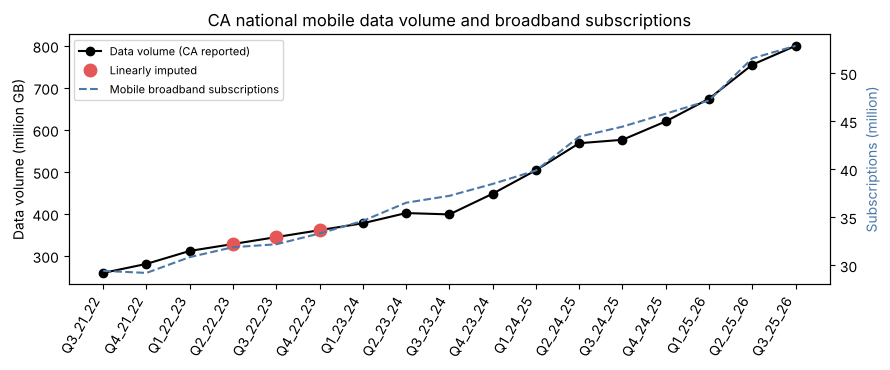

In [4]:
# Figure 4.3: data volume (left axis) and broadband subscriptions (right axis) by quarter.
# plt.subplots creates a figure and one set of axes (ax); figsize is width x height in inches.
fig, ax = plt.subplots(figsize=(9, 3.8))
q = df_temporal['Quarter'].astype(str)       # quarter labels as plain text for the x-axis
# Dividing by 1e6 (one million) makes the axis read in millions of GB.
# The format string 'k-o' means black ('k') solid line ('-') with round markers ('o').
ax.plot(q, df_temporal['Total_Data_Consumed_GB'] / 1e6, 'k-o', label='Data volume (CA reported)')
# Boolean mask of the imputed quarters, used to draw larger red dots (ms = marker size) on top.
imp = df_temporal['imputed_quarter'] == 1
ax.plot(q[imp], df_temporal.loc[imp, 'Total_Data_Consumed_GB'] / 1e6, 'o', color='#e45756', ms=9, label='Linearly imputed')
ax.set_ylabel('Data volume (million GB)')
# twinx() adds a second y-axis on the right that shares the same x-axis. It is needed because
# subscriptions and data volume are measured in different units and on different scales.
ax2 = ax.twinx()
ax2.plot(q, df_temporal['Total_Mobile_Broadband'] / 1e6, '--', color='#4c78a8', label='Mobile broadband subscriptions')
ax2.set_ylabel('Subscriptions (million)', color='#4c78a8')
ax.set_title('CA national mobile data volume and broadband subscriptions')
# Each axis keeps its own legend entries (handles h and labels l); join both lists so that all
# three lines appear in one legend box.
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc='upper left')
# Rotate the quarter labels by 60 degrees so they do not overlap; tight_layout() trims margins.
plt.setp(ax.get_xticklabels(), rotation=60, ha='right'); plt.tight_layout()
# save_figure writes Outputs/figures/F4.03_ca_national_series.png; plt.show() draws it here.
save_figure('4.03', 'ca_national_series'); plt.show()

**How to read Figure 4.3.** The black line with dots is the national data volume in millions of GB (left axis). The three larger red dots are the linearly imputed quarters, which lie on a straight line between their reported neighbours. The dashed blue line is mobile broadband subscriptions in millions (right axis, labelled in blue). Because the two lines use different axes, compare their **shapes** (how steeply each one rises, and where it bends) rather than their heights.

The next cell saves the completed series, including `q_idx`, the `imputed_quarter` flag and the growth column, as `Data/processed/ca_quarterly_telemetry_imputed.csv` for the later notebooks.

In [5]:
# Save the completed CA series for the later notebooks. index=False stops pandas from writing the
# row numbers (0, 1, 2, ...) as an extra unnamed column.
df_temporal.to_csv(PROCESSED + 'ca_quarterly_telemetry_imputed.csv', index=False)
print(f"[saved] {PROCESSED}ca_quarterly_telemetry_imputed.csv")

[saved] Data/processed/ca_quarterly_telemetry_imputed.csv


## Part B: Ookla Open Data (Local Demand Signal)
The CA series is national only. To place demand in space, this study uses **Ookla Open Data** mobile performance tiles: zoom-16 web-Mercator tiles (about 600 m) with the number of speed tests, the number of unique devices, and average download/upload speed and latency for each quarter.

- **Source:** `s3://ookla-open-data/parquet/performance/type=mobile/`, one file per calendar quarter (2022 Q1 to 2026 Q1 = the 17 CA quarters).
- **Licence:** CC BY-NC-SA 4.0. Cite as: *Speedtest® by Ookla® Global Fixed and Mobile Network Performance Maps. Based on analysis by Ookla of Speedtest Intelligence® data for [quarter]. Provided by Ookla and accessed [date].*

**Key terms used in Part B**
- **Speed test:** a measurement that a user starts in the Speedtest app. The phone downloads and uploads test data and records how fast this happened. Ookla publishes the results only in aggregated form, per map tile and per quarter.
- **Web-Mercator tiles and zoom level:** online maps cut the world into square tiles. At zoom 0 a single tile covers the whole world, and each extra zoom level splits every tile into four (2 × 2). At zoom 16 a tile is about 600 m across near the equator; at zoom 7 a tile is roughly 300 km across.
- **Quadkey:** a tile's identifier written as a string of digits 0–3, one digit per zoom level; each digit says which of the four quarters of the parent tile to step into. A zoom-16 quadkey therefore has 16 digits, and its first 7 digits are the quadkey of the zoom-7 tile that contains it. The extractor uses this to find Kenyan tiles quickly.
- **Columns used later:** `tests` (number of speed tests in the tile in that quarter), `devices` (number of distinct devices that ran them), `avg_d_kbps` and `avg_u_kbps` (average download and upload speed in kilobits per second), and `avg_lat_ms` (average latency in milliseconds). **Mbps** means megabits per second, and 1 Mbps = 1,000 kbps. **Latency** is the time a small message takes to travel to the test server and back, so lower is better.
- **Why this is a demand signal:** a tile appears in a quarter only if at least one test was run there, and more tests and devices mean more people actively using mobile internet in that place. It is a *sample* of activity, not a measurement of total traffic.

### Step 3: Extraction (optional, already done)
The global files are large, so the Kenya extract is provided in `Data/raw_ookla/`. Set `RUN_DOWNLOAD = True` to rebuild it from the source (needs internet access, `curl` and `pyarrow`; it downloads 17 global files of about 180–200 MB each, roughly 3 GB in total). The extractor keeps tiles whose quadkey starts with one of the zoom-7 prefixes covering a rectangle around Kenya (latitude −4.9 to 5.1, longitude 33.8 to 42.0).

**How the extractor `download_ookla_kenya` works** (it runs only when `RUN_DOWNLOAD = True`; by default the cell just reads the ready-made Kenya file):
1. **Match calendar quarters to CA quarters.** Ookla names its files by calendar year and quarter, while the CA uses financial-year labels. The dictionary `CA_QUARTER` links the two, for example calendar 2022 Q1 (January–March 2022) to `Q3_21_22`.
2. **Find the zoom-7 tiles around Kenya.** The inner function `tile` converts a latitude and longitude into zoom-7 tile numbers with the standard web-Mercator formula, and `to_qk` turns tile numbers into a quadkey. The north-west and south-east corners of the rectangle give the range of tiles, and every tile in that range becomes one 7-digit prefix.
3. **Download and filter each quarter.** For each of the 17 quarters it downloads the global file with `curl` and reads it chunk by chunk (Parquet "row groups"), so the whole file never has to fit in memory. It keeps rows whose quadkey starts with one of the prefixes, converts each quadkey to its tile centre with `quadkey_to_latlon` (from `project_config`), and keeps tiles whose centre lies inside the rectangle.
4. **Combine and save.** The kept rows from all quarters are stacked with `pd.concat` and saved as `ookla_mobile_kenya_all_quarters.csv`.

**Parquet** is a compressed, column-based file format for large tables. It is smaller and faster to read than CSV and it remembers the data type of every column; pandas reads and writes it through the `pyarrow` package.

**How to read the output.** The printed line gives the number of **tile-quarters** inside the rectangle (one row = one tile in one quarter) and the number of distinct quarters, which should be 17. These rows still include tiles just across the border, which Step 4 removes.

In [6]:
# Switch for the optional download. Leave it False to use the extract already in Data/raw_ookla/.
RUN_DOWNLOAD = False

# Dictionary {key: value}: key = (calendar year, calendar quarter) as Ookla names its files,
# value = the matching CA financial-year label. CA Q1 = Jul-Sep, Q2 = Oct-Dec, Q3 = Jan-Mar and
# Q4 = Apr-Jun, so calendar Q1 of 2022 is CA Q3 of 2021/22.
CA_QUARTER = {(2022, 1): 'Q3_21_22', (2022, 2): 'Q4_21_22', (2022, 3): 'Q1_22_23', (2022, 4): 'Q2_22_23',
              (2023, 1): 'Q3_22_23', (2023, 2): 'Q4_22_23', (2023, 3): 'Q1_23_24', (2023, 4): 'Q2_23_24',
              (2024, 1): 'Q3_23_24', (2024, 2): 'Q4_23_24', (2024, 3): 'Q1_24_25', (2024, 4): 'Q2_24_25',
              (2025, 1): 'Q3_24_25', (2025, 2): 'Q4_24_25', (2025, 3): 'Q1_25_26', (2025, 4): 'Q2_25_26',
              (2026, 1): 'Q3_25_26'}

# Download Ookla's global quarterly files and keep only the tiles in a rectangle around Kenya.
# The arguments have default values: the output folder, the rectangle in degrees (lat0 to lat1
# from south to north, lon0 to lon1 from west to east) and the zoom level z of the prefix filter.
def download_ookla_kenya(out_dir=RAW_OOKLA, lat0=-4.9, lat1=5.1, lon0=33.8, lon1=42.0, z=7):
    # Imported here rather than at the top because they are only needed when downloading.
    import math, subprocess
    import pyarrow.parquet as pq
    # Latitude/longitude -> (x, y) tile numbers at zoom z (standard web-Mercator formula).
    # n = 2**z tiles along each side; x counts from west to east and y from north to south.
    def tile(lat, lon):
        n = 2 ** z
        return int((lon + 180) / 360 * n), int((1 - math.asinh(math.tan(math.radians(lat))) / math.pi) / 2 * n)
    # (x, y) tile numbers -> quadkey string. For each zoom level, starting from the coarsest, the
    # digit is (bit of x) + 2 * (bit of y): >> shifts the bits right and & 1 keeps the last bit.
    def to_qk(x, y):
        return ''.join(str(((x >> (z - i - 1)) & 1) | (((y >> (z - i - 1)) & 1) << 1)) for i in range(z))
    # Tile numbers of the north-west corner (lat1, lon0) and the south-east corner (lat0, lon1).
    (x0, y0), (x1, y1) = tile(lat1, lon0), tile(lat0, lon1)
    # Set comprehension: one quadkey for every zoom-7 tile in the rectangle. A set {...} holds
    # each value once and makes the membership check (.isin below) quick.
    prefixes = {to_qk(x, y) for x in range(x0, x1 + 1) for y in range(y0, y1 + 1)}
    parts = []                                   # filtered chunks, combined at the end
    # .items() yields (key, value) pairs; the key (yr, qtr) is unpacked into two names at once.
    for (yr, qtr), caq in CA_QUARTER.items():
        # Build the file address. {(qtr - 1) * 3 + 1:02d} is the first month of the quarter
        # written with two digits (01, 04, 07 or 10), which is how Ookla names its files.
        url = (f"https://ookla-open-data.s3.amazonaws.com/parquet/performance/type=mobile/year={yr}/quarter={qtr}/"
               f"{yr}-{(qtr - 1) * 3 + 1:02d}-01_performance_mobile_tiles.parquet")
        tmp = out_dir + 'tmp.parquet'
        # Run curl to download the file (-sS: quiet but still report errors; --retry 4: try again
        # up to 4 times). check=True stops the notebook with an error if the download fails.
        subprocess.run(['curl', '-sS', '--retry', '4', '-o', tmp, url], check=True)
        with pq.ParquetFile(tmp) as pf:          # closed before os.remove (needed on Windows)
            # List comprehension: every column name except 'tile' (the tile outline stored as
            # text, which is large and not needed because the quadkey identifies the tile).
            cols = [c for c in pf.schema_arrow.names if c != 'tile']
            # Read one row group (chunk) at a time to keep memory use low.
            for rg in range(pf.num_row_groups):
                d = pf.read_row_group(rg, columns=cols).to_pandas()
                # .str[:z] takes the first z characters of each quadkey, and .isin(prefixes) is
                # True when that prefix is one of the zoom-7 tiles around Kenya.
                d = d[d['quadkey'].str[:z].isin(prefixes)]
                if d.empty:                      # nothing near Kenya in this chunk: skip it
                    continue
                # .map applies quadkey_to_latlon to every quadkey, giving (lat, lon) pairs;
                # zip(*...) splits the pairs into a sequence of latitudes and one of longitudes.
                d['lat'], d['lon'] = zip(*d['quadkey'].map(quadkey_to_latlon))
                # Zoom-7 tiles reach beyond the rectangle, so trim to the exact rectangle.
                # .between(a, b) is True when a <= value <= b; & means both must be True.
                d = d[d.lat.between(lat0, lat1) & d.lon.between(lon0, lon1)]
                # Label every row with its calendar year, calendar quarter and CA quarter.
                d['year'], d['quarter'], d['ca_quarter'] = yr, qtr, caq
                parts.append(d)
        os.remove(tmp)                           # delete the large global file
        print(yr, qtr, caq, 'done')
    # Stack all filtered chunks into one table; ignore_index=True renumbers the rows from 0.
    out = pd.concat(parts, ignore_index=True)
    out.to_csv(out_dir + 'ookla_mobile_kenya_all_quarters.csv', index=False)
    return out

if RUN_DOWNLOAD:
    download_ookla_kenya()

# Load the Kenya extract (rebuilt by the function above only if RUN_DOWNLOAD is True).
ookla = pd.read_csv(RAW_OOKLA + 'ookla_mobile_kenya_all_quarters.csv')
# {len(ookla):,} prints the number with thousands separators; .nunique() counts distinct values.
print(f"Ookla tile-quarters in the bounding box: {len(ookla):,} across {ookla['ca_quarter'].nunique()} quarters")

Ookla tile-quarters in the bounding box: 80,517 across 17 quarters


### Step 4: Clip to Kenya's national border
The rectangle also covers parts of Uganda, Tanzania, Ethiopia and Somalia. Twin border towns (Busia, Namanga, Moyale, Mandera) would otherwise add foreign speed tests to Kenyan demand. A tile is kept only if its centre lies inside Kenya, using the same border test as Notebook 01.

**How the code does it.**
- The same tile usually appears in several quarters, so the border test is run once per distinct tile centre: `drop_duplicates()` keeps one row per (`lat`, `lon`) pair in the small table `tile_xy`.
- `in_kenya` (from `project_config`) returns True when a point falls inside Kenya. It uses the time-zone boundary polygons of the `timezonefinder` package, which follow OpenStreetMap national borders; Kenya is the only country in the `Africa/Nairobi` zone.
- `merge` copies the True/False result back onto every tile-quarter with the same coordinates, much like a lookup (VLOOKUP) in a spreadsheet.
- Only rows inside Kenya are kept. Each row then receives the integer time index `q_idx` from Part A, so the Ookla tiles and the CA series share the same quarter numbering. The `assert` line stops the notebook with an error if any Ookla quarter has no matching CA quarter.

**How to read the output.** The printed line gives two shares of the rectangle's data that lay outside Kenya: the share of tile-quarters and the share of speed tests. Together they show how much foreign activity would have been counted as Kenyan demand without this step. The two shares can differ because some tiles have many more tests than others.

In [7]:
# One row per distinct tile centre (the same tile repeats across quarters). in_kenya checks the
# points one by one, so it is run once per tile rather than once per tile-quarter.
tile_xy = ookla[['lat', 'lon']].drop_duplicates()
# True if the tile centre lies inside Kenya's border (see in_kenya in project_config).
tile_xy['in_kenya'] = in_kenya(tile_xy['lat'], tile_xy['lon'])
# Join the flag onto every tile-quarter with the same lat and lon (a lookup-style join).
ookla = ookla.merge(tile_xy, on=['lat', 'lon'])
# ~ flips True/False, so ~ookla.in_kenya marks rows OUTSIDE Kenya. The mean of True/False values
# is the share that is True, and the format {...:.1%} prints a share as a percentage, 1 decimal.
print(f"Tiles outside Kenya removed: {(~ookla.in_kenya).mean():.1%} of tile-quarters, "
      f"{ookla.loc[~ookla.in_kenya, 'tests'].sum() / ookla['tests'].sum():.1%} of tests")
# Keep only the rows inside Kenya and drop the helper column. .copy() makes a fresh, independent
# table, so adding columns later does not act on (or warn about) a slice of the old one.
ookla = ookla[ookla.in_kenya].drop(columns='in_kenya').copy()
# Give each Ookla row the same integer quarter index as the CA series. dict(zip(a, b)) builds a
# lookup {quarter label: q_idx}, and .map() replaces each row's label with its number.
ookla['q_idx'] = ookla['ca_quarter'].map(dict(zip(df_temporal['Quarter'].astype(str), df_temporal['q_idx'])))
# Safety check: stop with an error if any label found no match (it would be NaN after .map).
assert ookla['q_idx'].notna().all()

Tiles outside Kenya removed: 12.6% of tile-quarters, 9.5% of tests


### Step 5: Coverage of the crowdsourced data by quarter
Ookla data come from users who choose to run a speed test, so coverage is uneven: dense in cities, thin in remote areas. This is why Notebook 03 aggregates tiles to sub-counties and smooths the demand share over time.

**What the step does.** **Crowdsourced** data are collected by members of the public rather than by a planned survey, so where and when data exist depends on who chooses to take part. This step summarises, for each quarter, how much Ookla data there is inside Kenya (Table 4.4) and shows where it is (Figure 4.4). It tells the reader how far the local demand signal can be trusted and in which quarters it is thinner.

**How the code does it.**
- `groupby(['q_idx', 'ca_quarter'])` splits the rows into one group per quarter, and `.agg(...)` computes one summary per group. Each item is written as `new_name=(column, function)`: `tiles` counts the rows (`'size'`), `tests` and `devices` are sums, and `median_tests_per_tile` is the median number of tests in a tile.
- `mean_download_Mbps` is a **test-weighted mean**: each tile's average download speed is multiplied by its number of tests (`w_dl`), these products are added up and divided by the total number of tests, and the result is divided by 1,000 to convert kbps to Mbps. Weighting matters because a tile average based on many tests is more reliable than one based on a single test.
- The helper column `w_dl` is then removed from `ookla`, so it is not saved with the clean data.

**How to read Table 4.4.** One row per quarter. `tiles` is the number of tiles inside Kenya with at least one test, `tests` and `devices` are totals over those tiles, `median_tests_per_tile` shows how thin a typical tile is, and `mean_download_Mbps` is the average download speed per test. `devices` is summed over tiles, so a phone that ran tests in two tiles is counted twice: read it as an indicator of activity, not an exact count of users. A low median number of tests per tile is the main warning sign, because it means that most single tiles are too noisy to use on their own; this is why tiles are pooled into sub-counties in Notebook 03.

Table 4.4: Ookla mobile tiles inside Kenya by quarter
[saved] Outputs/tables/T4.04_ookla_coverage_by_quarter.csv


,q_idx,Quarter,tiles,tests,devices,median_tests_per_tile,mean_download_Mbps
0,0,Q3_21_22,3211,11803,5794,2.0,25.73
1,1,Q4_21_22,3191,11760,6029,2.0,25.37
2,2,Q1_22_23,3059,11970,5945,2.0,25.04
3,3,Q2_22_23,3266,13810,6554,2.0,38.08
4,4,Q3_22_23,3170,12735,6167,2.0,48.02
5,5,Q4_22_23,3015,12509,6187,2.0,50.27
6,6,Q1_23_24,3463,14203,7203,2.0,43.93
7,7,Q2_23_24,3734,15918,7525,2.0,55.65
8,8,Q3_23_24,3508,13609,6841,2.0,47.69
9,9,Q4_23_24,3738,17978,7929,2.0,59.53


[saved] Outputs/figures/F4.04_ookla_coverage.png


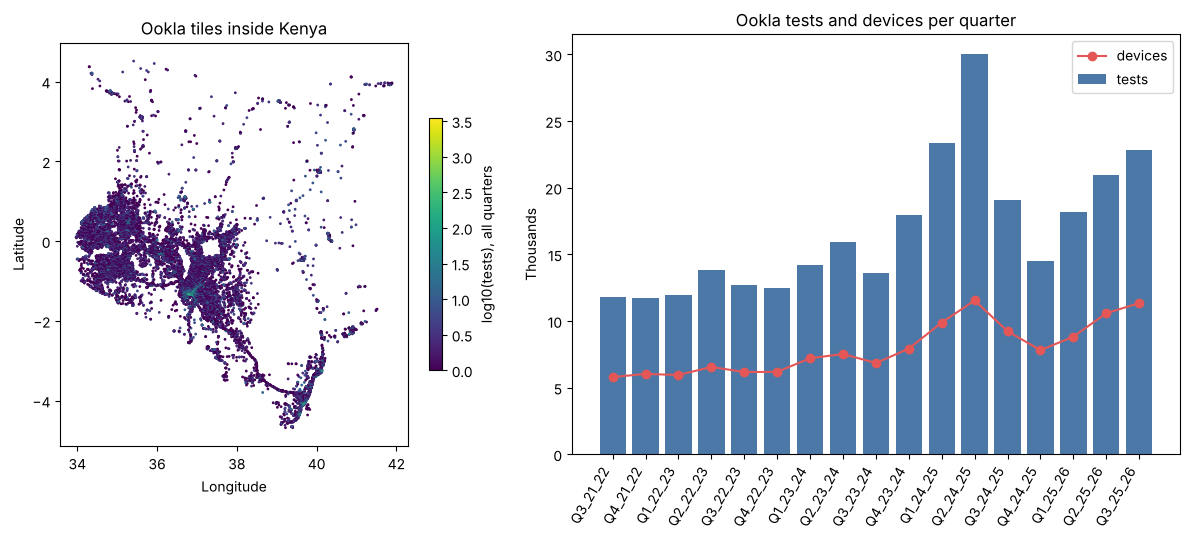

In [8]:
# Helper column: tile average download speed (kbps) x number of tests in the tile. Summing it and
# dividing by the total tests gives the average speed per test rather than per tile.
ookla['w_dl'] = ookla['avg_d_kbps'] * ookla['tests']
# groupby + agg: one output row per quarter. Each argument is new_name=(column, function), and
# 'size' counts the rows, i.e. the tiles with at least one test in that quarter.
# reset_index() turns the group labels (q_idx, ca_quarter) back into ordinary columns.
t44 = (ookla.groupby(['q_idx', 'ca_quarter'])
       .agg(tiles=('quadkey', 'size'), tests=('tests', 'sum'), devices=('devices', 'sum'),
            median_tests_per_tile=('tests', 'median'), w_dl=('w_dl', 'sum'))
       .reset_index())
# Test-weighted mean download speed; dividing by 1000 converts kbps to Mbps.
t44['mean_download_Mbps'] = t44['w_dl'] / t44['tests'] / 1000
# Tidy the table: drop the helper sum, rename ca_quarter to Quarter (as in Table 4.3), round.
t44 = t44.drop(columns='w_dl').rename(columns={'ca_quarter': 'Quarter'}).round(2)
ookla = ookla.drop(columns='w_dl')           # remove the helper column from the tile data too
print("Table 4.4: Ookla mobile tiles inside Kenya by quarter")
display(save_table(t44, '4.04', 'ookla_coverage_by_quarter'))

# Figure 4.4: map of the tiles (left panel) and tests/devices per quarter (right panel).
# 1 row x 2 columns of panels, so ax is a pair: ax[0] is the left panel and ax[1] the right.
# width_ratios makes the right panel 1.4 times as wide as the left one.
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5), gridspec_kw={'width_ratios': [1, 1.4]})
# Total tests per tile centre over all 17 quarters (one row per tile).
tiles_all = ookla.groupby(['lat', 'lon'])['tests'].sum().reset_index()
# Scatter plot of tile centres (longitude on x, latitude on y) coloured by log10(tests); s=1
# draws tiny dots. A log scale is used as a few city tiles have far more tests than the rest.
s = ax[0].scatter(tiles_all.lon, tiles_all.lat, c=np.log10(tiles_all.tests), s=1, cmap='viridis')
# Colour key for the map; shrink=0.6 makes it 60% of its default length.
plt.colorbar(s, ax=ax[0], shrink=0.6, label='log10(tests), all quarters')
# 'equal' aspect draws one degree of latitude and one of longitude at the same length, so the
# shape of the country is not stretched.
ax[0].set_aspect('equal'); ax[0].set_title('Ookla tiles inside Kenya'); ax[0].set_xlabel('Longitude'); ax[0].set_ylabel('Latitude')
# Bars: tests per quarter; line with dots: devices per quarter (both / 1000, i.e. thousands).
ax[1].bar(t44['Quarter'], t44['tests'] / 1000, color='#4c78a8', label='tests')
ax[1].plot(t44['Quarter'], t44['devices'] / 1000, 'o-', color='#e45756', label='devices')
ax[1].set_ylabel('Thousands'); ax[1].set_title('Ookla tests and devices per quarter'); ax[1].legend()
plt.setp(ax[1].get_xticklabels(), rotation=60, ha='right'); plt.tight_layout()
save_figure('4.04', 'ookla_coverage'); plt.show()

**How to read Figure 4.4.**
- **Left panel (map):** every dot is one Ookla tile inside Kenya, drawn at its centre. The colour shows the total number of tests in that tile over all quarters on a log10 scale: 0 means 1 test, 1 means 10 tests, 2 means 100 tests, and so on (dark purple = few tests, yellow = many). Look for dense clusters in and around towns and along main roads, against scattered single dots in sparsely populated areas. Empty areas are not necessarily areas without mobile use; they are areas where nobody ran a speed test.
- **Right panel:** blue bars are the number of tests per quarter and the red line is the number of devices per quarter, both in thousands. Quarters with fewer tests give a noisier local demand signal, which is one reason Notebook 03 smooths the demand share over time.

## Step 6: Export and Hand-Off to Notebook 03
The clean Ookla table (only tiles inside Kenya, with the shared quarter index `q_idx`) is saved as `Data/processed/ookla_kenya_clean.parquet`. Parquet is used instead of CSV because it is smaller, faster to load and keeps each column's data type. The CA series was already saved in Part A as `Data/processed/ca_quarterly_telemetry_imputed.csv`. The printed line confirms the file name and how many tile-quarters inside Kenya were kept.

In [9]:
# Save the clean Ookla table in Parquet format (pandas uses pyarrow for this); index=False drops
# the row numbers.
ookla.to_parquet(PROCESSED + 'ookla_kenya_clean.parquet', index=False)
print(f"[saved] {PROCESSED}ookla_kenya_clean.parquet ({len(ookla):,} tile-quarters inside Kenya)")

[saved] Data/processed/ookla_kenya_clean.parquet (70,378 tile-quarters inside Kenya)


### Summary of Notebook 02
- **CA series:** 17 quarters, 3 of them (Q2–Q4 2022/23) linearly imputed and flagged. This is the national total that Notebook 03 distributes across sub-counties. It sets the size of each sub-county's load and gap in GB, but not which sub-counties are stressed, so the imputation does not touch the stress label.
- **Ookla:** quarterly tiles inside Kenya. Coverage is thin per tile, so it is used as a **relative** demand weight after aggregation, not as an absolute traffic measure.
- **Next:** Notebook 03 assigns the Ookla tiles to the sites from Notebook 01 and downscales the CA totals into a sub-county × quarter panel.

**Key design choices in brief (useful for the defence)**
- **Why impute instead of dropping the three quarters?** Notebook 03 needs a national total for every quarter to distribute, and the models in Notebook 04 read runs of consecutive quarters. Dropping the quarters would leave holes in both; imputing and flagging keeps the sequence complete while keeping the estimate visible.
- **Why does the imputation not affect which sub-counties are stressed?** The main stress label is the top 20% of sub-counties *within each quarter*. Scaling a quarter's national total up or down changes every sub-county's load in that quarter by the same factor, so the ranking, and therefore the label, stays the same.
- **Why use both sources?** The CA series gives a trustworthy national size but no location; Ookla gives location but only a small, self-selected sample of activity. Combining them uses each for what it measures best.
- **Why clip to the border?** Speed tests in neighbouring countries' border towns are not Kenyan demand, and leaving them in would inflate demand in Kenyan border sub-counties.